# CO₂ hydrate onset with dissolved salts and MEG

Reproduce the reported **44 bara** case with **1 kg water, 100 g NaCl, 50 g MEG and 10 mol CO₂**.
Use the controls and pressure curves to see how salt and MEG change the incipient hydrate
temperature and how a free CO₂-rich phase changes from vapour-like to dense.
The example uses **Electrolyte CPA (Statoil)**, mixing rule **10** and explicit dissolved ions.
A 1:1 amount of Na⁺ or K⁺ and Cl⁻ represents each mole of added salt. The fluid is non-reactive.

The notebook runs the Java solver from the NeqSim default branch, pinned to the
[merged source revision](https://github.com/equinor/neqsim/commit/33057ab304332df9c97b3a1a0f0ec56c1dd73397).
Run the cells in order in a fresh CPU runtime in Colab. The first run builds the Java JAR.

In [1]:
import hashlib
from importlib import metadata
import os
from pathlib import Path
import re
import shutil
import subprocess
import sys

NEQSIM_SOURCE_REF = "33057ab304332df9c97b3a1a0f0ec56c1dd73397"
JPYPE_VERSION = "1.7.1"
VALIDATED_LOCAL_JAR_SHA256 = "8241d0cf7e6783a94ca4b2bb5d2992e4c2262bde293c5bda3bd92a1ecd73ca29"

try:
    installed_jpype = metadata.version("JPype1")
except metadata.PackageNotFoundError:
    installed_jpype = None

if installed_jpype != JPYPE_VERSION:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", f"JPype1=={JPYPE_VERSION}"],
        check=True,
    )

local_jar = os.environ.get("CO2_HYDRATE_NEQSIM_JAR")
if local_jar:
    jar_path = Path(local_jar).resolve(strict=True)
else:
    source_dir = Path(f"neqsim-{NEQSIM_SOURCE_REF[:12]}").resolve()
    source_dir.mkdir(exist_ok=True)
    if not (source_dir / ".git").is_dir():
        subprocess.run(["git", "init", "--quiet"], cwd=source_dir, check=True)

    verifiable_checkout = subprocess.run(
        ["git", "rev-parse", "--verify", "HEAD"], cwd=source_dir, capture_output=True
    )
    if verifiable_checkout.returncode != 0:
        repo_url = "https://github.com/equinor/neqsim.git"
        fetch = ["git", "fetch", "--quiet", "--depth=1", repo_url, NEQSIM_SOURCE_REF]
        subprocess.run(fetch, cwd=source_dir, check=True)
        subprocess.run(
            ["git", "checkout", "--quiet", "--detach", "FETCH_HEAD"],
            cwd=source_dir,
            check=True,
        )

    checkout_ref = subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=source_dir, text=True
    ).strip()
    if checkout_ref != NEQSIM_SOURCE_REF:
        raise RuntimeError("The NeqSim checkout does not match the pinned revision.")

    javac_path = shutil.which("javac")
    java_major = 0
    if javac_path:
        javac_version = subprocess.check_output([javac_path, "-version"], text=True)
        java_major = int(re.search(r"javac (\d+)", javac_version).group(1))

    if java_major < 17:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "-qq", "openjdk-17-jdk"], check=True)
        javac_path = shutil.which("javac")

    os.environ["JAVA_HOME"] = str(Path(javac_path).resolve().parent.parent)
    wrapper = source_dir / "mvnw"
    jar_path = source_dir / "target" / "neqsim-3.29.0.jar"
    if not jar_path.is_file():
        build = [
            "bash", str(wrapper), "-B", "-q", "-Dmaven.test.skip=true",
            "-Dmaven.javadoc.skip=true", "package",
        ]
        subprocess.run(build, cwd=source_dir, check=True)

os.environ["NEQSIM_JVM_AUTOSTART"] = "0"

import jpype

if not jpype.isJVMStarted():
    jpype.addClassPath(str(jar_path))
    jpype.startJVM("-Xmx768m", "-XX:ActiveProcessorCount=2")

ElectrolyteCPA = jpype.JClass("neqsim.thermo.system.SystemElectrolyteCPAstatoil")
Operations = jpype.JClass("neqsim.thermodynamicoperations.ThermodynamicOperations")
JavaSystem = jpype.JClass("java.lang.System")
JavaFile = jpype.JClass("java.io.File")
Co2BrineEquilibrium = jpype.JClass(
    "neqsim.thermodynamicoperations.flashops.CO2BrinePhaseEquilibrium"
)
for engine_class in (ElectrolyteCPA, Operations, Co2BrineEquilibrium):
    code_source = engine_class.class_.getProtectionDomain().getCodeSource()
    loaded_jar = Path(str(JavaFile(code_source.getLocation().toURI()).getCanonicalPath()))
    if loaded_jar != jar_path:
        raise RuntimeError("The JVM loaded a different NeqSim build. Restart the runtime.")

digest = hashlib.sha256(jar_path.read_bytes()).hexdigest()
if local_jar and digest != VALIDATED_LOCAL_JAR_SHA256:
    raise RuntimeError("The supplied local JAR differs from the validated build.")

print(f"NeqSim 3.29.0 from master: {NEQSIM_SOURCE_REF}")
print(f"JAR SHA-256: {digest}")
print(f"Java {JavaSystem.getProperty('java.version')} · JPype {jpype.__version__}")

NeqSim 3.29.0 from master: 33057ab304332df9c97b3a1a0f0ec56c1dd73397
JAR SHA-256: 8241d0cf7e6783a94ca4b2bb5d2992e4c2262bde293c5bda3bd92a1ecd73ca29
Java 21.0.13 · JPype 1.7.1


## Specify the mass basis

The reported recipe doses each additive per kilogram of water. The alternative recipe defines
each percentage on its separate binary solution basis. On that basis, 10 wt% NaCl means
111.11 g NaCl per kilogram water, and 5 wt% MEG means 52.63 g MEG per kilogram water.
Each dosage is converted to grams of additive before the fluid is built.

The helper takes **grams per kilogram water** directly so the two recipes are explicit.
It uses independent fresh fluids for each result and by default requires a material CO₂-rich phase
alongside the aqueous phase.

In [2]:
import math

MOLAR_MASS_G_PER_MOL = {"water": 18.01528, "NaCl": 58.44277, "KCl": 74.5513, "MEG": 62.06784}
CATION = {"NaCl": "Na+", "KCl": "K+"}


def grams_per_kg_water(binary_weight_percent):
    """Convert the mass percent of solute in its binary water solution to g/kg water."""
    return 1000.0 * binary_weight_percent / (100.0 - binary_weight_percent)


def hydrate_point(
    pressure_bara, salt, salt_g, meg_g, co2_mol,
    initial_temperature_c=None, require_co2_phase=True,
):
    """Return an audited incipient hydrate state for a fresh 1 kg water feed."""
    salt_mol = salt_g / MOLAR_MASS_G_PER_MOL[salt]
    feed_mol = {
        "CO2": co2_mol,
        "water": 1000.0 / MOLAR_MASS_G_PER_MOL["water"],
        CATION[salt]: salt_mol,
        "Cl-": salt_mol,
    }
    if meg_g > 0.0:
        feed_mol["MEG"] = meg_g / MOLAR_MASS_G_PER_MOL["MEG"]

    fluid = ElectrolyteCPA(283.15, pressure_bara)
    for name, amount in feed_mol.items():
        fluid.addComponent(name, amount)
    fluid.setMixingRule(10)
    fluid.setMultiPhaseCheck(True)
    fluid.setHydrateCheck(True)

    operations = Operations(fluid)
    if initial_temperature_c is None:
        operations.hydrateFormationTemperature()
    else:
        operations.hydrateFormationTemperature(273.15 + initial_temperature_c)

    diagnostics = operations.getOperation().getDiagnostics()
    temperature_c = fluid.getTemperature("C")
    if not math.isfinite(temperature_c) or not diagnostics.isConverged():
        raise RuntimeError("The hydrate calculation did not converge.")
    saturated_boundary = diagnostics.isSaturatedCO2Boundary()
    if require_co2_phase and not saturated_boundary:
        raise RuntimeError("There is no verified saturated CO₂ hydrate boundary.")

    phases = [fluid.getPhase(index) for index in range(fluid.getNumberOfPhases())]
    co2_rich_phases = [
        phase
        for phase in phases
        if str(phase.getType()) != "AQUEOUS" and phase.getComponent("CO2").getx() > 0.5
    ]
    rich_phase = next(iter(co2_rich_phases), None)

    total_mol = fluid.getTotalNumberOfMoles()
    closure_errors = []
    for name, amount in feed_mol.items():
        overall_fraction = sum(
            phase.getBeta() * phase.getComponent(name).getx() for phase in phases
        )
        closure_errors.append(abs(total_mol * overall_fraction - amount))
    max_closure_mol = max(closure_errors)
    hydrate_residual = abs(diagnostics.getHydrateResidual())
    fluid_residual = diagnostics.getFluidFugacityResidual()
    phase_charge = diagnostics.getChargeResidual()
    assert max_closure_mol < 1.0e-8
    assert hydrate_residual <= 1.0e-6
    if saturated_boundary:
        assert rich_phase is not None
        assert fluid_residual <= 1.0e-8
    assert phase_charge <= 1.0e-10

    return {
        "temperature_c": temperature_c,
        "co2_density_kg_m3": rich_phase.getDensity() if rich_phase is not None else None,
        "co2_phase_label": str(rich_phase.getType()) if rich_phase is not None else "—",
        "fluid_phases": "+".join(str(phase.getType()) for phase in phases),
        "saturated_boundary": saturated_boundary,
        "hyd_residual": hydrate_residual,
        "fluid_residual": fluid_residual,
        "max_closure_mol": max_closure_mol,
    }

## Calculate the reported case and controls

The CO₂-rich phase density is useful alongside the phase label. For these calculations the
label identifies NeqSim's requested EOS root. Use the calculated density to distinguish
vapour-like and dense liquid-like CO₂.

In [3]:
from IPython.display import Markdown, display

test_cases = [
    ("Reported recipe", 44.0, 100.0, 50.0),
    ("Lower-salt control", 44.0, 50.0, 50.0),
    ("No MEG control", 44.0, 100.0, 0.0),
    ("Separate binary wt% bases", 44.0, grams_per_kg_water(10), grams_per_kg_water(5)),
    ("Nearby pressure", 40.0, 100.0, 50.0),
    ("Nearby pressure", 48.0, 100.0, 50.0),
]
results = []
for label, pressure, salt_g, meg_g in test_cases:
    endpoint = hydrate_point(pressure, "NaCl", salt_g, meg_g, 10.0)
    results.append({"label": label, "pressure": pressure, "salt_g": salt_g,
                    "meg_g": meg_g, **endpoint})

table = [
    "| Case | bara | NaCl g | MEG g | Onset °C | CO₂-rich density kg/m³ |",
    "|---|---:|---:|---:|---:|---:|",
]
for result in results:
    table.append(
        f"| {result['label']} | {result['pressure']:.1f} | {result['salt_g']:.2f} | "
        f"{result['meg_g']:.2f} | {result['temperature_c']:.4f} | "
        f"{result['co2_density_kg_m3']:.1f} |"
    )
display(Markdown("\n".join(table)))

reported, salt_control, no_meg, binary_bases, at_40, at_48 = results
repeat = hydrate_point(44.0, "NaCl", 100.0, 50.0, 10.0, initial_temperature_c=10.0)
assert abs(reported["temperature_c"] - repeat["temperature_c"]) < 2.0e-4
assert binary_bases["temperature_c"] < reported["temperature_c"]
assert reported["temperature_c"] < min(salt_control["temperature_c"], no_meg["temperature_c"])
assert at_40["temperature_c"] <= reported["temperature_c"] <= at_48["temperature_c"]
guess_difference = abs(reported['temperature_c'] - repeat['temperature_c'])
print(f"Default vs 10 °C initial guess: {guess_difference:.2e} K")
max_closure = max(row['max_closure_mol'] for row in results)
print(f"Largest original-feed component balance error: {max_closure:.2e} mol")
print(f"Largest absolute hydrate residual: {max(r['hyd_residual'] for r in results):.2e}")
max_fluid_residual = max(row['fluid_residual'] for row in results)
print(f"Largest absolute molecular log-fugacity residual: {max_fluid_residual:.2e}")
print(f"Reported case CO₂-rich phase label: {reported['co2_phase_label']}")

Default vs 10 °C initial guess: 3.76e-08 K
Largest original-feed component balance error: 7.11e-15 mol
Largest absolute hydrate residual: 1.63e-09
Largest absolute molecular log-fugacity residual: 7.58e-12
Reported case CO₂-rich phase label: GAS


| Case | bara | NaCl g | MEG g | Onset °C | CO₂-rich density kg/m³ |
|---|---:|---:|---:|---:|---:|
| Reported recipe | 44.0 | 100.00 | 50.00 | 2.7083 | 798.1 |
| Lower-salt control | 44.0 | 50.00 | 50.00 | 5.6751 | 772.2 |
| No MEG control | 44.0 | 100.00 | 0.00 | 4.7990 | 780.1 |
| Separate binary wt% bases | 44.0 | 111.11 | 52.63 | 1.9030 | 804.7 |
| Nearby pressure | 40.0 | 100.00 | 50.00 | 2.6630 | 792.4 |
| Nearby pressure | 48.0 | 100.00 | 50.00 | 2.7530 | 803.5 |

## Follow the pressure dependence

Compare three recipes at fixed overall CO₂ loading. Salt and MEG change the aqueous
water fugacity and depress the hydrate equilibrium temperature at 44 bara.
The lower panel tracks the calculated density of the CO₂-rich phase in the reported recipe.
Use each computed point as a screening result. The shaded interval brackets the change
in calculated phase density between sampled pressures.

Verified saturated states: 21
CO₂-rich phase density: 102 kg/m³ at 37 bara
CO₂-rich phase density: 792 kg/m³ at 40 bara


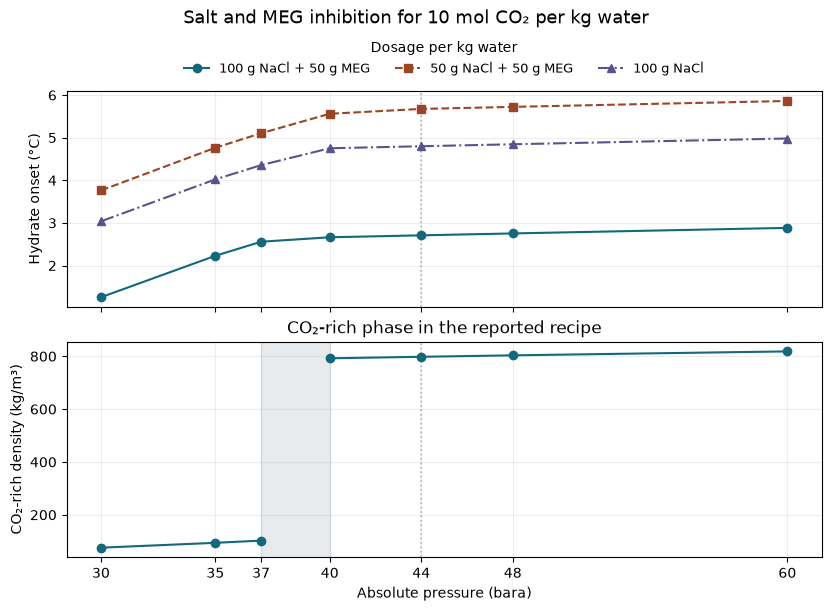

In [4]:
import matplotlib.pyplot as plt

pressures_bara = [30.0, 35.0, 37.0, 40.0, 44.0, 48.0, 60.0]
recipes = [
    ("100 g NaCl + 50 g MEG", 100.0, 50.0, "#12687c", "o", "-", reported),
    ("50 g NaCl + 50 g MEG", 50.0, 50.0, "#9a4525", "s", "--", salt_control),
    ("100 g NaCl", 100.0, 0.0, "#56538d", "^", "-.", no_meg),
]
sweep = {}
figure, (onset_axis, density_axis) = plt.subplots(
    2, 1, sharex=True, figsize=(8.2, 6.0), constrained_layout=True
)

for label, salt_g, meg_g, color, marker, linestyle, at_44 in recipes:
    points = []
    for pressure in pressures_bara:
        if pressure == 44.0:
            point = at_44
        else:
            point = hydrate_point(pressure, "NaCl", salt_g, meg_g, 10.0)
        points.append(point)
    sweep[label] = points
    onset_axis.plot(
        pressures_bara,
        [point["temperature_c"] for point in points],
        label=label, color=color, marker=marker, linestyle=linestyle,
    )

reported_curve = sweep["100 g NaCl + 50 g MEG"]
reported_density = [point["co2_density_kg_m3"] for point in reported_curve]
split_index = pressures_bara.index(40.0)
density_axis.axvspan(37.0, 40.0, color="#526775", alpha=0.13)
for region in (slice(None, split_index), slice(split_index, None)):
    density_axis.plot(
        pressures_bara[region], reported_density[region], color="#12687c", marker="o",
    )
figure.suptitle("Salt and MEG inhibition for 10 mol CO₂ per kg water", fontsize=13)
onset_axis.set_ylabel("Hydrate onset (°C)")
onset_axis.legend(
    title="Dosage per kg water", loc="lower center", bbox_to_anchor=(0.5, 1.02),
    ncol=3, fontsize=9, frameon=False,
)
density_axis.set(
    xlabel="Absolute pressure (bara)",
    ylabel="CO₂-rich density (kg/m³)",
    title="CO₂-rich phase in the reported recipe",
    xticks=pressures_bara,
)
for axis in (onset_axis, density_axis):
    axis.grid(alpha=0.22)
    axis.axvline(44.0, color="#555f66", alpha=0.45, linewidth=1.2, linestyle=":")
plt.show()

sweep_points = [point for points in sweep.values() for point in points]
assert all(point["saturated_boundary"] for point in sweep_points)
assert reported_density[2] < reported_density[3]
print(f"Verified saturated states: {len(sweep_points)}")
print(f"CO₂-rich phase density: {reported_density[2]:.0f} kg/m³ at 37 bara")
print(f"CO₂-rich phase density: {reported_density[3]:.0f} kg/m³ at 40 bara")

## Check whether a free CO₂ phase exists

A hydrate search at fixed overall composition can give an aqueous-only fluid state when
the supplied CO₂ is too low to leave a separate phase. Saturated hydrate curves use points
with an aqueous phase and a free CO₂-rich phase. Compare the model diagnostics at 100 bara
for the same water, salt and MEG recipe at two different CO₂ loadings.

In [5]:
phase_rows = [
    "| CO₂ feed (mol/kg water) | Fluid phase labels | Saturated CO₂ boundary |",
    "|---:|---|---|",
]
inventory_controls = {}
for co2_mol in (0.5, 10.0):
    result = hydrate_point(
        100.0, "NaCl", 100.0, 50.0, co2_mol,
        initial_temperature_c=0.0, require_co2_phase=False,
    )
    inventory_controls[co2_mol] = result
    phase_rows.append(
        f"| {co2_mol:.1f} | {result['fluid_phases']} | "
        f"{'Yes' if result['saturated_boundary'] else 'No'} |"
    )
assert inventory_controls[0.5]["fluid_phases"] == "AQUEOUS"
assert not inventory_controls[0.5]["saturated_boundary"]
assert inventory_controls[10.0]["saturated_boundary"]
display(Markdown("\n".join(phase_rows)))

| CO₂ feed (mol/kg water) | Fluid phase labels | Saturated CO₂ boundary |
|---:|---|---|
| 0.5 | AQUEOUS | No |
| 10.0 | OIL+AQUEOUS | Yes |

## Compare the KCl point at 11.3 bara

Dholabhai, Kalogerakis and Bishnoi (1993), Tables I and III, report **269.02 K
(−4.13 °C)** for **10.02 wt% KCl** on a water-plus-salt basis at **1.130 MPa absolute**.
The calculation below uses the same composition basis and an assumed CO₂ charge. The report
gives a measured vapour–aqueous–hydrate equilibrium. The simulated CO₂ charge is chosen
to leave a free CO₂ phase.

[Primary source, DOI 10.1021/je00012a045](https://doi.org/10.1021/je00012a045)

In [6]:
reported_kcl = hydrate_point(11.3, "KCl", 100.0, 0.0, 2.805906013)
binary_kcl = hydrate_point(11.3, "KCl", grams_per_kg_water(10.0), 0.0, 2.805906013)
measured_kcl = hydrate_point(11.3, "KCl", grams_per_kg_water(10.02), 0.0, 10.0)
measured_temperature_c = 269.02 - 273.15
difference_k = measured_kcl["temperature_c"] - measured_temperature_c

print(f"100 g KCl/kg water: {reported_kcl['temperature_c']:.4f} °C")
print(f"10.00 wt% KCl in water plus salt: {binary_kcl['temperature_c']:.4f} °C")
print(f"NeqSim with the published KCl recipe: {measured_kcl['temperature_c']:.4f} °C")
print(f"Measured with the published KCl recipe: {measured_temperature_c:.4f} °C")
print(f"Calculated minus measured: {difference_k:+.4f} K")

100 g KCl/kg water: -3.4593 °C
10.00 wt% KCl in water plus salt: -3.8240 °C
NeqSim with the published KCl recipe: -3.8324 °C
Measured with the published KCl recipe: -4.1300 °C
Calculated minus measured: +0.2976 K


## Interpretation and scope

At 44 bara the reported recipe gives about **2.71 °C** and a dense free CO₂-rich phase. Both the salt basis and the amount of CO₂ supplied affect how the result should be read. For practice, change one additive dose and compare the onset and the phase diagnostics.

The 44 bara runs check the numerical onset, the free CO₂-rich phase, original-feed conservation,
charge balance and fluid/hydrate fugacity closure. The KCl point is a literature comparison for
a separate salt-only system. The NaCl–MEG recipe has no accompanying experimental onset
temperature in this example.

The model covers incipient equilibrium in simple salt/glycol solutions. Ice, salt precipitation,
hydrate growth rates and the effects of solids or proprietary drilling-fluid additives require
separate modeling or experimental validation.

[Reported issue #5026](https://github.com/equinor/neqsim/issues/5026) ·
[Merged Java fix #5027](https://github.com/equinor/neqsim/pull/5027) ·
[KCl model qualification](https://github.com/equinor/neqsim/issues/4234) ·
[Broader hydrate tutorial](https://github.com/EvenSol/NeqSim-Colab/blob/master/notebooks/flowassurance/co2_hydrate_brines_and_drilling_fluids.ipynb)